# E1 – Convergence with the number of clustered time steps

Target K ∈ {24, 48, 96, 192, 384, 768, 1460, 2920}. Results are plotted against the *actual* number of clustered steps, since the target is raised to 2 × the number of series of the largest stage and extremes are added on top.

- demo (1 stage): M1, M2 (M1b = M1 for one stage), solved.
- ms3 (2 stages): M1, M1b, M2, solved.
- swissx (4 stages): M1, M1b, M2, clustering only.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import romlab as rl

pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

def try_run(*args):
    try:
        return rl.run(*args)
    except Exception as exc:  # failed runs are reported, not hidden
        return {"error": str(exc).strip().splitlines()[-1]}

print({k: v for k, v in rl.VARIANTS.items()})

{'M1': 'd436c9b7', 'M1b': 'f69e03d5', 'M2': 'bd1a0c89'}


In [2]:
K = [24, 48, 96, 192, 384, 768, 1460, 2920]
VARS = {"demo": ["M1", "M2"], "ms3": ["M1", "M1b", "M2"], "swissx": ["M1", "M1b", "M2"]}
MODE = {"demo": "rom", "ms3": "rom", "swissx": "cluster"}
prof = {c: rl.run(c, "M0", "profiles") for c in VARS}
full = {c: rl.run(c, "M0", "full") for c in ("demo", "ms3")}
rows, met = [], []
for c, vs in VARS.items():
    for v in vs:
        for k in K:
            r = try_run(c, v, MODE[c], k)
            row = {"case": c, "variant": v, "target": k}
            if "error" in r:
                row["error"] = r["error"]; rows.append(row); continue
            row["num_ts"] = r["num_ts"]
            row["secs_cluster"] = r["secs_cluster"]
            st = rl.stage_summary(r, prof[c]["num_horizon_ts"])
            row["phantom"] = int(st.phantom.sum())
            if MODE[c] == "rom":
                row.update(rl.solution_compare(full[c], r))
            m = rl.series_metrics(prof[c], r)
            m = m[~m.constant]
            for col in ["wsum_err", "max_err", "min_err", "dc_nrmse", "chr_nrmse"]:
                row[col] = m[col].abs().mean()
            rows.append(row)
res = pd.DataFrame(rows)
print("full solve time [s]:", {c: round(full[c]["secs_solve"]) for c in full})
res

full solve time [s]: {'demo': 76, 'ms3': 144}


,case,variant,target,num_ts,secs_cluster,phantom,obj_err,cap_abs_diff_rel,techs_flipped,secs_solve,wsum_err,max_err,min_err,dc_nrmse,chr_nrmse
0,demo,M1,24,60,23.2,0,0.06675,0,0,19.03,0.007613,0,6.438e-10,0.1193,0.2257
1,demo,M1,48,76,23.59,0,0.0618,0,0,18.85,0.005738,0,6.438e-10,0.113,0.2199
2,demo,M1,96,124,25.72,0,0.05928,0,0,20.13,0.003541,0,6.438e-10,0.1002,0.2076
3,demo,M1,192,220,29.35,0,0.05693,0,0,22.32,0.001679,0,6.438e-10,0.08492,0.1918
4,demo,M1,384,412,38.1,0,0.05097,0,0,27.44,0.0004531,0,6.438e-10,0.06913,0.1733
5,demo,M1,768,796,52.71,0,0.04495,0,0,41.82,0.0001557,0,6.438e-10,0.05378,0.1522
6,demo,M1,1460,1488,82.3,0,0.03859,0,0,62.91,8.209e-05,0,6.438e-10,0.03861,0.1295
7,demo,M1,2920,2947,143.1,0,0.03052,0,0,63.66,7.459e-05,0,6.438e-10,0.02286,0.0998
8,demo,M2,24,60,7.218,0,0.05737,0,0,18.87,9.802e-17,0,0,0.1428,0.2304
9,demo,M2,48,76,6.935,0,0.05763,0,0,18.85,1.015e-16,0,0,0.1299,0.2233


## Model-level convergence (demo, ms3)

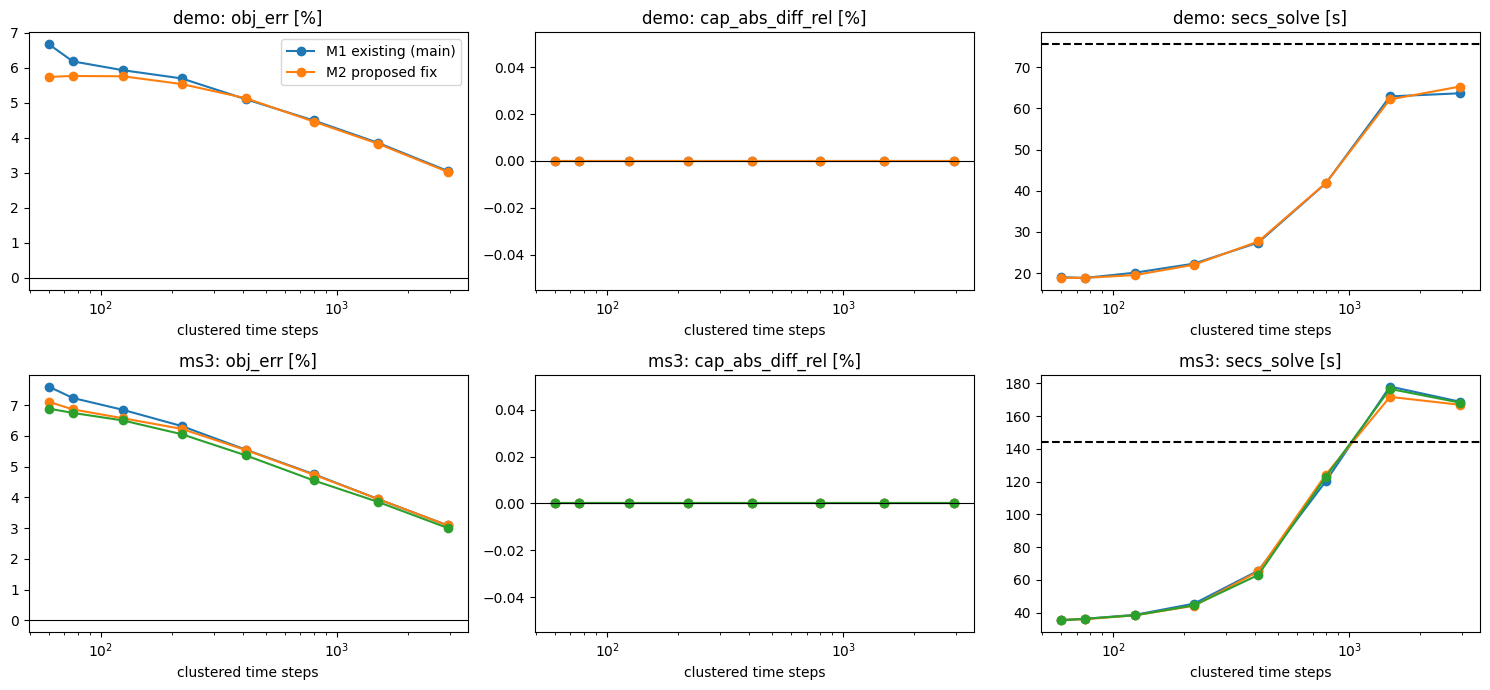

In [3]:
cols = ["obj_err", "cap_abs_diff_rel", "secs_solve"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(["demo", "ms3"]):
    for j, col in enumerate(cols):
        ax = axes[i, j]
        for v in VARS[c]:
            d = res[(res.case == c) & (res.variant == v)].dropna(subset=["num_ts"])
            y = d[col] * (100 if col != "secs_solve" else 1)
            ax.plot(d.num_ts, y, marker="o", label=rl.LABELS[v])
        if col == "secs_solve":
            ax.axhline(full[c]["secs_solve"], color="k", ls="--", label="M0 full")
        else:
            ax.axhline(0, color="k", lw=0.8)
        ax.set_xscale("log"); ax.set_xlabel("clustered time steps")
        ax.set_title(f"{c}: {col}" + (" [%]" if col != "secs_solve" else " [s]"))
axes[0, 0].legend(); plt.tight_layout()

## Input-level convergence (all cases)

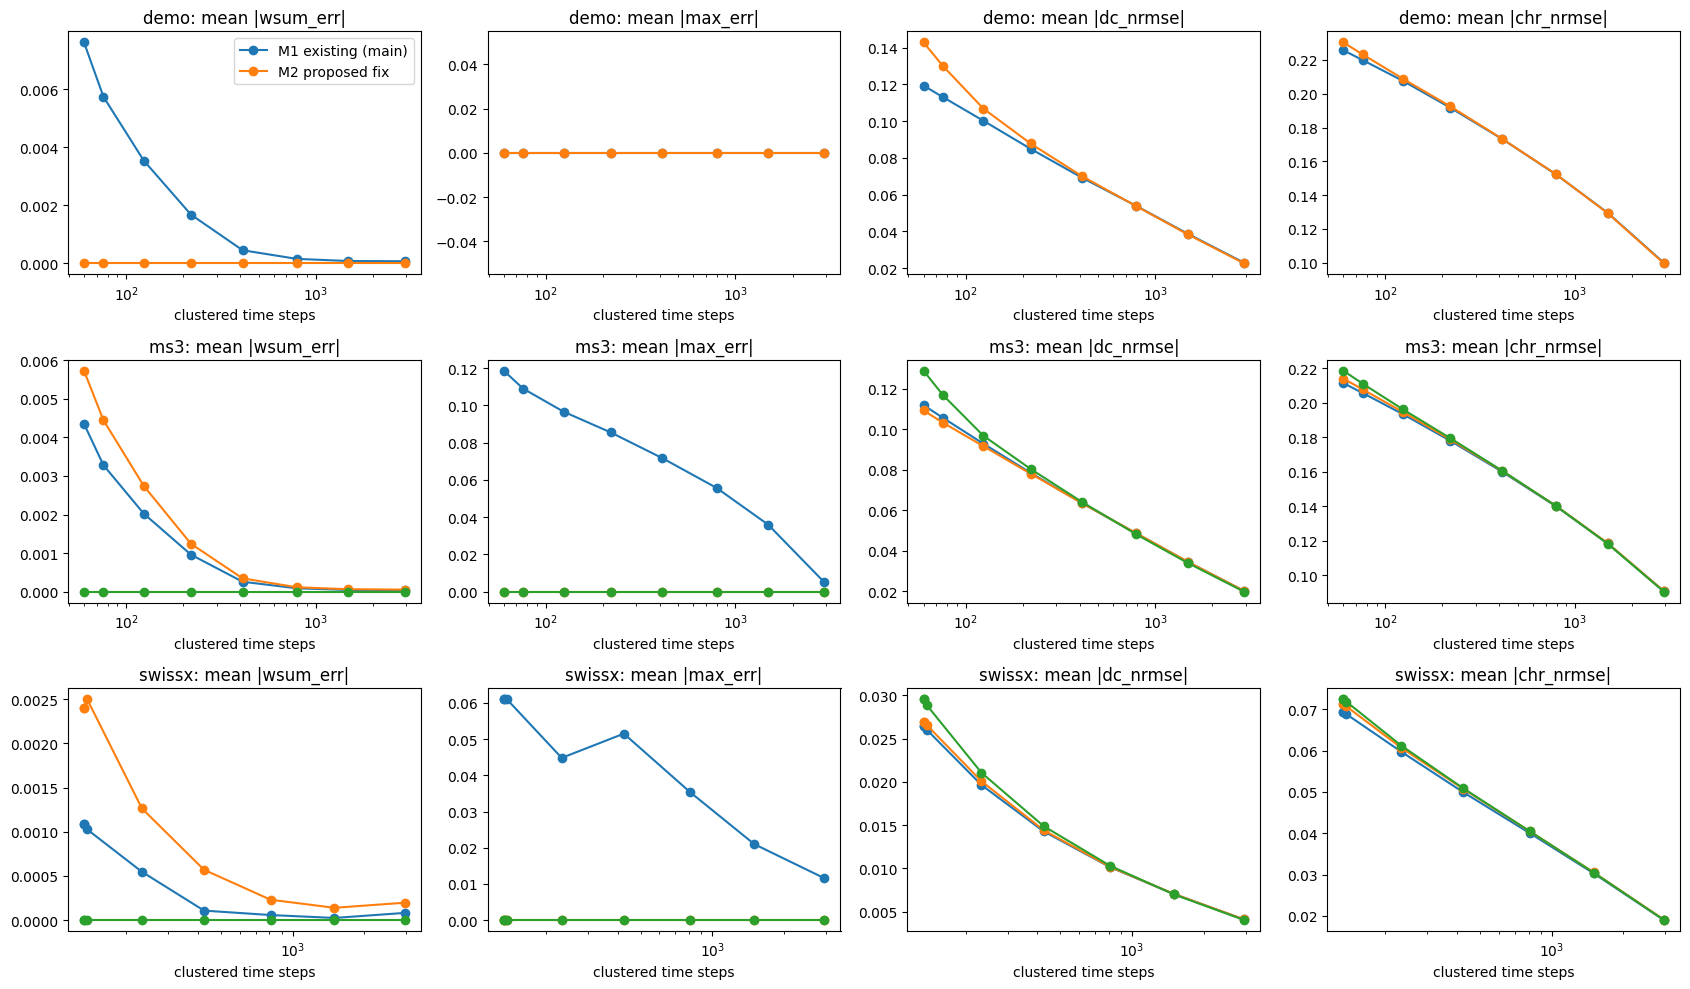

In [4]:
cols = ["wsum_err", "max_err", "dc_nrmse", "chr_nrmse"]
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for i, c in enumerate(["demo", "ms3", "swissx"]):
    for j, col in enumerate(cols):
        ax = axes[i, j]
        for v in VARS[c]:
            d = res[(res.case == c) & (res.variant == v)].dropna(subset=["num_ts"])
            ax.plot(d.num_ts, d[col], marker="o", label=rl.LABELS[v])
        ax.set_xscale("log"); ax.set_title(f"{c}: mean |{col}|")
        ax.set_xlabel("clustered time steps")
axes[0, 0].legend(); plt.tight_layout()

## Findings (E1)

**Actual size.** The target is often not what the model gets. demo/ms3: a
target of 24 gives 60 steps (2 × 16 series + 28 extremes). SwissX: targets 24
and 48 both give 133 steps (2 × 46 series + 41 extremes); the 2 × series rule
dominates below ~100.

**Objective converges slowly.** demo, M2: +5.7 % at 60 steps, +5.5 % at 220,
+4.5 % at 796, +3.8 % at 1488 and still **+3.0 % at 2948 steps** (a third of
the year). ms3 behaves the same (+6.9 % → +3.1 %). The input-level errors fall
much faster (totals exact, duration curve error 0.14 → 0.02). So the ROM error
of these models is **not mainly a matter of how well the profiles are
represented**.

Likely cause: with typical *hours*, all hours of a cluster share one set of
operation variables. The storage energy level runs over the horizon, but its
in- and outflows are indexed by the clustered step
(`stor_tech_model.py`, `_con_stor_tech_charging_dynamic`), so the storage
charges or discharges by the same amount in every hour of a cluster, i.e. at
hours spread over the whole year. The structure is confirmed in the code; its
share of the objective error is still to be quantified (E7). This
restricts storage operation (and anything else that couples hours) and makes
the ROM more expensive. Typical days (M3) or downsampling (M4) keep the
chronology and may behave very differently. The weak decrease of
`chr_nrmse` (0.23 → 0.10) points the same way.

**Methods compared.** The three methods converge alike. M2 has a lower
objective error at small K (demo: 5.7 % vs 6.7 % at 60 steps; ms3: 6.9 % vs
7.6 %) and exact totals and peaks at every K. M1 loses up to 52 % of the peak
range in multi-stage models even at 1500 steps (SwissX: 8 %). M2's
duration-curve error is a bit higher at small K and equal from ~400 steps on.

**Clustering time.** M2 is much faster: SwissX 44–81 s vs 210–2300 s for
M1/M1b (tsam's extreme-period handling and the re-clustering are expensive);
demo 7–12 s vs 23–143 s.

**Solve time.** Full demo: 76 s, ms3: 144 s; ROM 19–65 s and 35–180 s. The
speed-up of the ROM is only 2–4× for these small models. Solve times were
measured with 6 runs in parallel and are only indicative.

**Next.** E7 (storage / coupling over time) and the alternative methods M3/M4
look more important than further tuning of the typical-hours clustering (E2,
E3). A model with free capacities is needed for the design comparison.
